
<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 16pt; text-align: center;"><strong>COU 07506 DIGITAL SIGNAL PROCESSING</strong></p>

<p style="font-size: 14pt; text-align: center;"><strong>WEEK 1 — LAB 0: SETTING UP THE DSP LABORATORY</strong></p>

<p style="font-size: 12pt;"><strong>Name:</strong> EBENEZER MUSSA ELIAS</p>

<p style="font-size: 12pt;"><strong>Registration No.:</strong> 24034458719</p>

<p style="font-size: 12pt;"><strong>Class:</strong> BENG24BE</p>

<p style="font-size: 12pt;"><strong>Group:</strong> 1A – BENG24BE – STREAM TWO</p>

<p style="font-size: 12pt;"><strong>Date:</strong> 25-11-2026</p>

<p style="font-size: 12pt;"><strong>Instructor checkpoints signed:</strong> [ ] 1 &nbsp;&nbsp; [ ] 2</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 14pt; text-align: center;"><strong>PRE-LAB PREPARATION</strong></p>

<p style="font-size: 12pt;"><strong>Pre-lab Question</strong></p>

<p style="font-size: 12pt;">List three devices you used today that contain DSP, and for each name one signal it processes.</p>

<p style="font-size: 12pt;"><strong>Answer</strong></p>

<p style="font-size: 12pt;"><strong>1. Smartphone:</strong> Processes digital audio signals during voice calls.</p>

<p style="font-size: 12pt;"><strong>2. Laptop:</strong> Processes audio signals captured by its microphone.</p>

<p style="font-size: 12pt;"><strong>3. Bluetooth earbuds:</strong> Process digital audio signals during music playback.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 14pt; text-align: center;"><strong>TASK 1.1 — FIRST NOTEBOOK</strong></p>

<p style="font-size: 12pt;"><strong>Objective</strong></p>

<p style="font-size: 12pt;">To generate and plot four elementary discrete-time signals using NumPy and Matplotlib:</p>

<ol style="font-size: 12pt;">
<li>Unit impulse</li>
<li>Unit step</li>
<li>Unit ramp</li>
<li>Real exponential signal</li>
</ol>

</div>


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

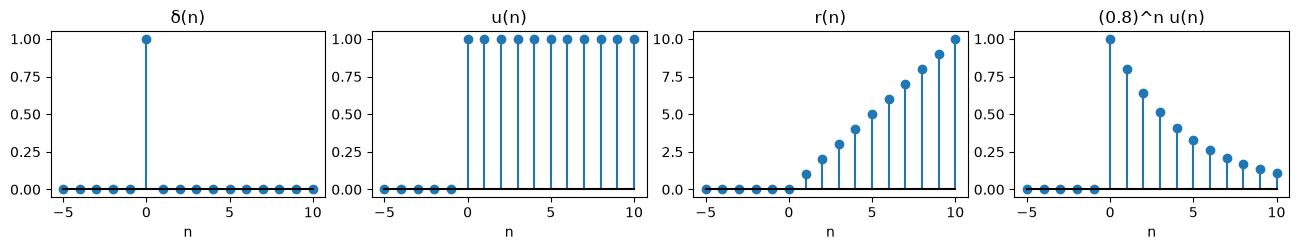

In [10]:
# Define the discrete-time index
n = np.arange(-5, 11)

# Generate elementary signals
delta = (n == 0).astype(float)       # Unit impulse
step = (n >= 0).astype(float)        # Unit step
ramp = n * step                      # Unit ramp
expo = 0.8**n * step                # Real exponential

# Create four subplots
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

# Plot each signal
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>Results and Observations</strong></p>

<p>The four elementary discrete-time signals were successfully generated and plotted using NumPy and Matplotlib.</p>

<ol>
<li><strong>Unit impulse:</strong> Has a value of 1 at n = 0 and zero elsewhere.</li>

<li><strong>Unit step:</strong> Has a value of 1 for n ≥ 0 and zero for n &lt; 0.</li>

<li><strong>Unit ramp:</strong> Starts at zero and increases linearly for positive values of n.</li>

<li><strong>Real exponential:</strong> Starts at 1 and decays towards zero because the base 0.8 is between 0 and 1.</li>
</ol>

<p>All four signals were represented using stem plots to show their discrete-time nature.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 14pt; text-align: center;"><strong>TASK 1.2 (PART A) — CHANGE THE PARAMETERS</strong></p>

<p><strong>Objective</strong></p>

<p>To investigate how the parameter <em>a</em> affects the shape and behaviour of a discrete-time exponential signal.</p>

</div>


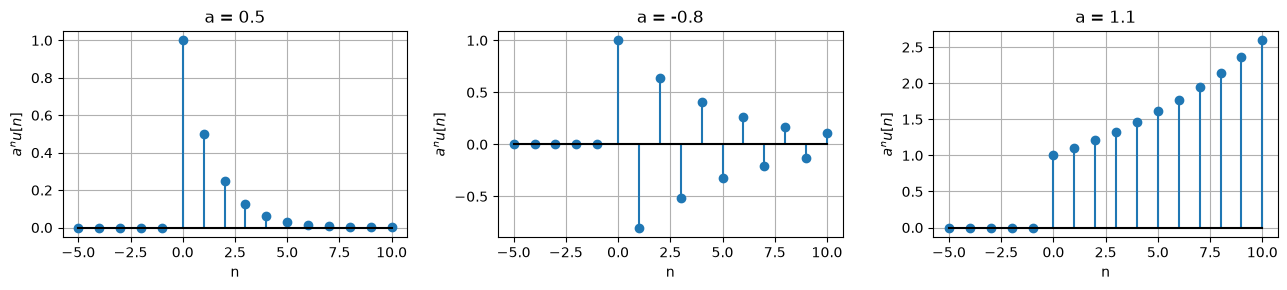

In [11]:
n = np.arange(-5, 11)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a ** n) * (n >= 0)

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel(r"$a^n u[n]$")
    ax.grid(True)

plt.tight_layout()
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>Results and Observations — Part A</strong></p>

<p>The three exponential signals were successfully generated and plotted.</p>

<ol>
<li><strong>a = 0.5:</strong> The signal decreases exponentially towards zero.</li>

<li><strong>a = −0.8:</strong> The signal alternates between positive and negative values while its magnitude decreases.</li>

<li><strong>a = 1.1:</strong> The signal increases exponentially as the sample index increases.</li>
</ol>

<p>The parameter <em>a</em> determines the behaviour of the exponential signal. Its magnitude influences growth or decay, while a negative value causes alternating signs.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>TASK 1.2 PART B — DISCRETE-TIME COSINE SIGNALS</strong></p>

<p>Investigate the periodicity of two discrete-time cosine signals with different normalized frequencies.</p>

</div>


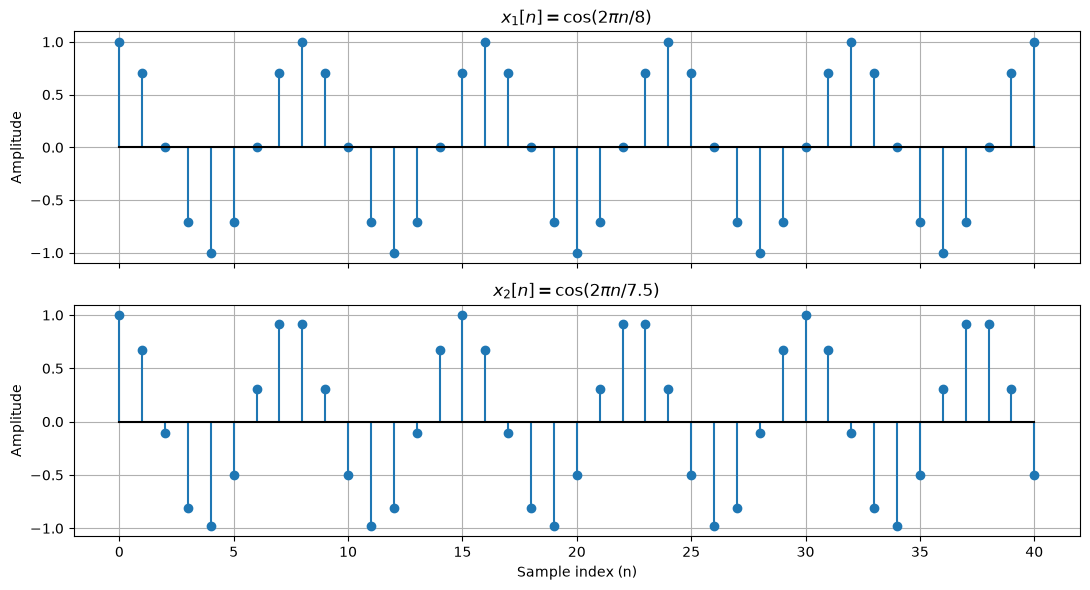

In [12]:
n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title(r"$x_1[n] = \cos(2\pi n/8)$")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title(r"$x_2[n] = \cos(2\pi n/7.5)$")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>Results and Observations — Part B</strong></p>

<p>Both discrete-time cosine signals were successfully generated and plotted.</p>

<ol>
<li>The first signal, cos(2πn/8), repeats after every 8 samples.</li>

<li>The second signal, cos(2πn/7.5), repeats after every 15 samples.</li>

<li>Both signals are periodic because their normalized frequencies are rational numbers.</li>
</ol>

<p>The fundamental periods are therefore 8 samples and 15 samples, respectively.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>PART C — NUMERICAL VERIFICATION OF PERIODICITY</strong></p>

<p>The fundamental periods of the two cosine signals are verified numerically by comparing each signal with a shifted version of itself.</p>

</div>


In [13]:
N1 = 8
N2 = 15

error1 = np.max(np.abs(x1[N1:] - x1[:-N1]))
error2 = np.max(np.abs(x2[N2:] - x2[:-N2]))

print("First signal:")
print(f"Fundamental period = {N1} samples")
print(f"Maximum difference = {error1:.12f}")

print("\nSecond signal:")
print(f"Fundamental period = {N2} samples")

print(f"Maximum difference = {error2:.12f}")

First signal:
Fundamental period = 8 samples
Maximum difference = 0.000000000000

Second signal:
Fundamental period = 15 samples
Maximum difference = 0.000000000000



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>CONCLUSION — TASK 1.2</strong></p>

<p>The experiments demonstrated that changing the exponential parameter affects whether a signal decays, alternates, or grows.</p>

<p>The cosine experiments confirmed that both signals are periodic. Their fundamental periods were verified numerically as 8 samples and 15 samples, respectively.</p>

<p>The numerical verification produced zero maximum difference for both signals, confirming their periodicity.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>STEP 2 — LOADING THE AUDIO RECORDING</strong></p>

<p>Load the recorded voice from the WAV file and inspect its sampling rate, duration, and number of samples.</p>

</div>


In [14]:
fname = "myVoice.wav"

fs, x = wavfile.read(fname)

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)
x = x / np.max(np.abs(x))

t = np.arange(len(x)) / fs

print(f"Sampling rate: {fs} Hz")
print(f"Duration: {len(x)/fs:.2f} seconds")
print(f"Number of samples: {len(x)}")

Sampling rate: 48000 Hz
Duration: 45.44 seconds
Number of samples: 2181119



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>STEP 3 — PLOTTING THE RECORDED AUDIO SIGNAL</strong></p>

<p>Visualize the recorded voice waveform in the time domain.</p>

</div>


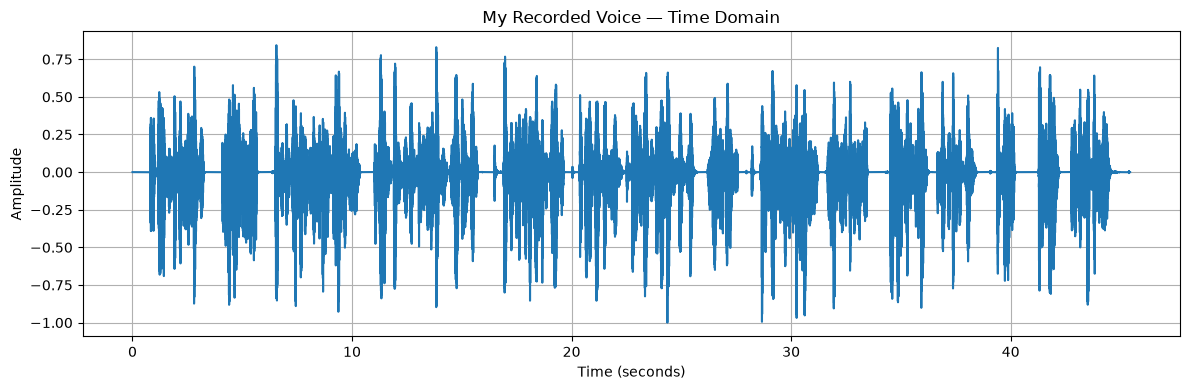

In [15]:
plt.figure(figsize=(12, 4))
plt.plot(t, x)

plt.title("My Recorded Voice — Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>RESULTS AND OBSERVATIONS</strong></p>

<p>The recorded voice was successfully loaded and plotted.</p>

<ul>
<li>Sampling frequency: 48,000 Hz.</li>
<li>Recording duration: 45.44 seconds.</li>
<li>Total samples: 2,181,119.</li>
<li>The waveform shows how the recorded sound amplitude changes over time.</li>
</ul>

</div>


In [16]:
from IPython.display import Audio, display

display(Audio(x, rate=fs))



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>RESULTS AND OBSERVATIONS</strong></p>

<p>The recorded voice was successfully loaded and plotted.</p>

<ul>
<li>Sampling frequency: 48,000 Hz.</li>
<li>Recording duration: 45.44 seconds.</li>
<li>Total samples: 2,181,119.</li>
<li>The waveform shows how the recorded sound amplitude changes over time.</li>
</ul>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p style="font-size: 12pt; text-align: center;"><strong>ANALYSIS QUESTIONS</strong></p>

<p><strong>1. What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?</strong></p>

<p>The sampling rate of my recorded audio signal was 48,000 Hz (48 kHz). This means that the recording system captures 48,000 individual samples every second. The sampling rate determines how frequently a continuous-time signal is measured and converted into a discrete-time signal.</p>

<p>To calculate the number of samples required to represent one minute of mono audio, the following relationship is used:</p>

<p style="text-align: center;"><strong>Number of samples = Sampling frequency × Duration</strong></p>

<p>Since one minute is equal to 60 seconds, substituting the values gives:</p>

<p style="text-align: center;">Number of samples = 48,000 × 60</p>

<p style="text-align: center;"><strong>Number of samples = 2,880,000</strong></p>

<p>Therefore, a one-minute mono audio recording sampled at 48 kHz requires 2,880,000 numerical sample values. This is the total number of samples rather than the actual file size, which also depends on the bit depth and encoding format used.</p>

<p><strong>2. Why is a stem plot more appropriate than a continuous line for x(n)?</strong></p>

<p>A stem plot is more appropriate for representing x(n) because it is a discrete-time signal. A discrete-time signal is defined only at specific sampling instants, usually represented by integer values of the index n. Each sample has a particular amplitude and corresponds to a specific point in time.</p>

<p>A stem plot represents each sample using a marker and a vertical line connecting it to the horizontal axis. This makes it easier to identify individual sample values and understand the discrete nature of the signal. On the other hand, a continuous line connects adjacent samples and may give the impression that the signal has values at every instant between the sampling points.</p>

<p>Therefore, a stem plot provides a more appropriate representation of x(n) because it shows the individual samples without suggesting continuity between them. It is particularly useful when studying discrete-time signals in Digital Signal Processing.</p>

<p><strong>3. For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?</strong></p>

<p>The property that would be violated is Bounded-Input, Bounded-Output (BIBO) stability. A system is said to be BIBO stable if every bounded input produces a bounded output. For a discrete-time Linear Time-Invariant (LTI) system, stability requires its impulse response to be absolutely summable. This condition is expressed as:</p>

<p style="text-align: center;">Sum of |h[n]|, from n = −∞ to ∞, must be less than infinity.</p>

<p>Consider a causal exponential impulse response given by:</p>

<p style="text-align: center;">h[n] = aⁿ × u[n]</p>

<p>Where a is the exponential factor, n is the discrete-time index, and u[n] is the unit step function. When a = 1.1, the impulse response becomes:</p>

<p style="text-align: center;">h[n] = (1.1)ⁿ × u[n]</p>

<p>Since the value of a is greater than one, the impulse response increases exponentially as n increases. To determine whether the system is stable, the absolute summability condition can be examined as follows:</p>

<p style="text-align: center;">1 + 1.1 + (1.1)² + (1.1)³ + ...</p>

<p>This is an infinite geometric series. Such a series converges to a finite value only when the absolute value of its common ratio is less than one. In this case, the common ratio is 1.1, which is greater than one. Therefore, the series diverges and its sum approaches infinity.</p>

<p>This means that the impulse response is not absolutely summable and consequently does not satisfy the BIBO stability condition. Therefore, the system is unstable because its impulse response grows continuously rather than decaying sufficiently with time.</p>

<p><strong>Conclusion:</strong> An LTI system with an impulse response defined by h[n] = (1.1)ⁿ × u[n] is BIBO unstable because its impulse response is not absolutely summable.</p>

</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p><strong>Recorded Audio File</strong></p>

<p>The original voice recording is saved in WAV format as <strong>myVoice.wav</strong>. The audio can be downloaded using the link below.</p>


<p><a href="https://github.com/Ebenezer-engineer/COU07506-labs-Copy/blob/main/myVoice.wav">Download the recorded audio (WAV)</a></p>


</div>



<div style="font-family: 'Times New Roman', Times, serif; font-size: 12pt; line-height: 1.5; text-align: justify;">

<p><strong>GitHub Repository</strong></p>

<p>The complete laboratory work and source files are available in the GitHub repository using the link below.</p>

<p><a href="https://github.com/Ebenezer-engineer/COU07506-labs-Copy?utm_source=chatgpt.com">View Week 1 DSP Laboratory Repository</a></p>

</div>
